In [28]:
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']   # Windows 常用
# plt.rcParams['font.sans-serif'] = ['PingFang SC']   # macOS
# plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei']  # Linux
plt.rcParams['axes.unicode_minus'] = False     # 正常显示负号

In [22]:
import pandas as pd
import numpy as np
# 指定字符格式读入数据
df1 = pd.read_csv(
    "events_clean.csv",
    encoding="utf-8",
    parse_dates=["event_time"],          # 时间列直接解析成 datetime
    dtype={
        "user_id": str,
        "event_id": str,
        "event_type": "category",
        "channel": "category",
    },
)

print(df1.dtypes)

event_id              object
user_id               object
event_time    datetime64[ns]
event_type          category
channel             category
device                object
amount               float64
date                  object
hour                   int64
dow                    int64
dow_name              object
week                  object
month                 object
dtype: object


In [6]:
pay = df1[df1["event_type"] == "pay"].copy()
pay.head()

,event_id,user_id,event_time,event_type,channel,device,amount,date,hour,dow,dow_name,week,month
11,E000012,U0001,2026-09-19 13:11:00,pay,App,iOS,1890.37,2026-09-19,13,5,周六,2026-09-14/2026-09-20,2026-09
24,E000025,U0003,2026-09-25 10:29:00,pay,小程序,Web,1053.75,2026-09-25,10,4,周五,2026-09-21/2026-09-27,2026-09
69,E000070,U0009,2026-09-25 19:50:00,pay,小程序,iOS,1874.86,2026-09-25,19,4,周五,2026-09-21/2026-09-27,2026-09
144,E000145,U0015,2026-09-24 16:39:00,pay,App,Android,804.06,2026-09-24,16,3,周四,2026-09-21/2026-09-27,2026-09
176,E000177,U0018,2026-10-01 10:03:00,pay,小程序,Web,1258.51,2026-10-01,10,3,周四,2026-09-28/2026-10-04,2026-10


In [7]:
pay["amount"].describe(percentiles=[.1, .25, .5, .75, .9, .95, .99])

count     758.000000
mean     1000.729908
std       569.785277
min        51.200000
10%       220.486000
25%       511.460000
50%       991.380000
75%      1485.177500
90%      1805.138000
95%      1891.991500
99%      1986.306200
max      1997.750000
Name: amount, dtype: float64

In [8]:
mean_v = pay["amount"].mean()
median_v = pay["amount"].median()
print(f"均值 {mean_v:.2f}, 中位数 {median_v:.2f}, 比值 {mean_v/median_v:.2f}")

均值 1000.73, 中位数 991.38, 比值 1.01


In [12]:
pay["amount_bin"] = pd.qcut(pay["amount"], q=10, duplicates="drop")
bin_stat = pay.groupby("amount_bin", observed=True)["amount"].agg(["count", "mean"])
bin_stat

,count,mean
amount_bin,,
"(51.199000000000005, 220.486]",76,143.066053
"(220.486, 407.79]",76,312.436447
"(407.79, 600.384]",76,501.152500
"(600.384, 775.038]",75,694.028800
"(775.038, 991.38]",76,882.306053
"(991.38, 1175.956]",76,1090.255658
"(1175.956, 1392.584]",75,1287.267467
"(1392.584, 1605.396]",76,1488.899342
"(1605.396, 1805.138]",76,1708.261842


<Axes: >

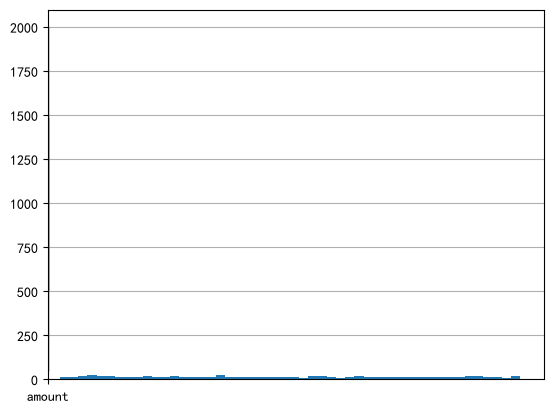

In [29]:
pay["amount"].hist(bins=50)
pay.boxplot(column="amount")

2、分组对比分析

In [ ]:
# 示例：按渠道对比
# 用户数 = nunique(user_id)
# 支付用户数 = event_type=='pay' 的 nunique(user_id)
# GMV = pay 事件 amount 之和
# 支付转化率 = 支付用户数 / 用户数
# 客单价 = GMV / 支付用户数

In [19]:
g = df1.groupby("channel", observed=True).agg(
    users=("user_id", "nunique"),
    events=("event_id", "count"),
    gmv=("amount", "sum"),
)
pay_users = df1[df1["event_type"] == "pay"].groupby("channel", observed=True)["user_id"].nunique()
g["pay_users"] = pay_users
g["pay_rate"] = g["pay_users"] / g["users"]
g["aov"] = g["gmv"] / g["pay_users"]
g.sort_values("pay_rate", ascending=False)

,users,events,gmv,pay_users,pay_rate,aov
channel,,,,,,
PC,368,4153,165623.77,133,0.361413,1245.291504
小程序,554,6356,241011.65,189,0.341155,1275.193915
App,869,10032,351917.85,277,0.318757,1270.461552


In [24]:
g["flag"] = np.where(g["users"] < 100, "样本不足", "")
g

,users,events,gmv,pay_users,pay_rate,aov,flag
channel,,,,,,,
App,869,10032,351917.85,277,0.318757,1270.461552,
PC,368,4153,165623.77,133,0.361413,1245.291504,
小程序,554,6356,241011.65,189,0.341155,1275.193915,


<Axes: title={'center': '各渠道支付转化率'}, xlabel='channel'>

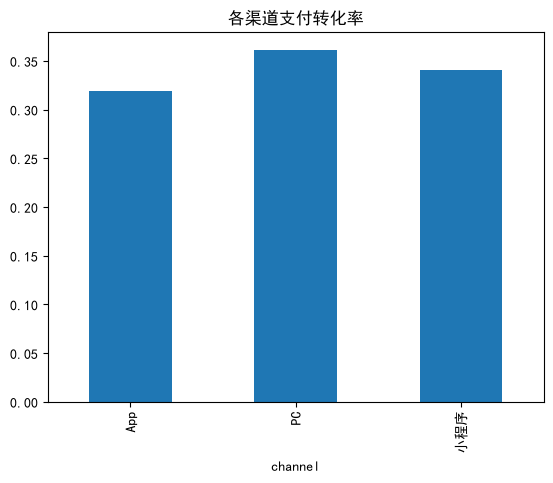

In [32]:
g["pay_rate"].plot(kind="bar", title="各渠道支付转化率")

3、透视表与交叉分析


In [34]:
pt = pd.pivot_table(
    df1[df1["event_type"] == "pay"],
    values="user_id",
    index="channel",
    columns="device",
    aggfunc="nunique",
    fill_value=0,
    margins=True,
    margins_name="合计",
)
pt

C:\Users\86180\AppData\Local\Temp\ipykernel_20200\3478651593.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pt = pd.pivot_table(


device,Android,Web,iOS,合计
channel,,,,
App,109,46,122,277
PC,66,24,43,133
小程序,71,44,74,189
合计,246,114,239,599


In [36]:
pt_pct = pt.drop("合计" , axis = "index").drop("合计", axis= "columns")
pt_pct = pt_pct.div(pt_pct.sum(axis="columns"), axis="index").round(3)
pt_pct

device,Android,Web,iOS
channel,,,
App,0.394,0.166,0.440
PC,0.496,0.180,0.323
小程序,0.376,0.233,0.392


In [37]:
pt_pct = pt.drop("合计" , axis = "index").drop("合计", axis= "columns")
pt_pct = pt_pct.div(pt_pct.sum(axis="index"), axis="columns").round(3)
pt_pct

device,Android,Web,iOS
channel,,,
App,0.443,0.404,0.51
PC,0.268,0.211,0.18
小程序,0.289,0.386,0.31


In [43]:
print("各格子样本量:\n", pt.drop("合计").drop("合计", axis='columns'))

各格子样本量:
 device   Android  Web  iOS
channel                   
App          109   46  122
PC            66   24   43
小程序           71   44   74


<Axes: xlabel='device', ylabel='channel'>

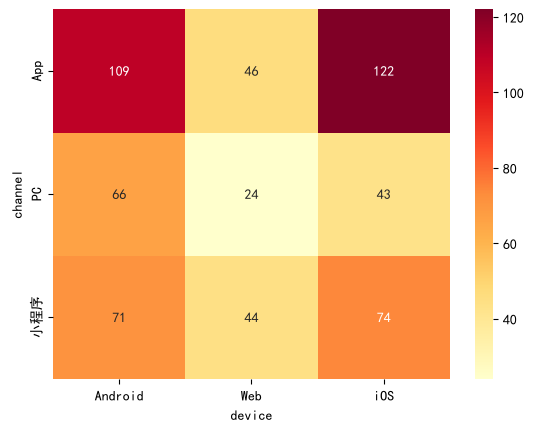

In [44]:
import seaborn as sns
sns.heatmap(pt.drop("合计").drop("合计", axis=1), annot=True, fmt=".0f", cmap="YlOrRd")

4、漏斗分析

In [46]:
steps = ["exposure", "click", "add_cart", "order", "pay"]
funnel = df1.groupby("event_type", observed=True)["user_id"].nunique().reindex(steps).fillna(0)
funnel_df = pd.DataFrame({"step": steps, "users": funnel.values})
funnel_df["step_rate"] = funnel_df["users"] / funnel_df["users"].shift(1)
funnel_df["overall_rate"] = funnel_df["users"] / funnel_df["users"].iloc[0]
funnel_df

,step,users,step_rate,overall_rate
0,exposure,1791,NaN,1.000000
1,click,1516,0.846454,0.846454
2,add_cart,1122,0.740106,0.626466
3,order,702,0.625668,0.391960
4,pay,599,0.853276,0.334450


In [49]:
funnel_df["lost_users"] = funnel_df["users"].shift(1) - funnel_df["users"]
funnel_df.sort_values("lost_users", ascending=False).head(2)

,step,users,step_rate,overall_rate,lost_users
3,order,702,0.625668,0.391960,420.0
2,add_cart,1122,0.740106,0.626466,394.0


In [51]:
ch_funnel = df1.groupby(["channel", "event_type"], observed=True)["user_id"].nunique().unstack()[steps]
ch_rate = ch_funnel.div(ch_funnel["exposure"], axis='index')
ch_rate.round(3)

event_type,exposure,click,add_cart,order,pay
channel,,,,,
App,1.0,0.842,0.610,0.374,0.319
PC,1.0,0.851,0.652,0.416,0.361
小程序,1.0,0.850,0.635,0.404,0.341


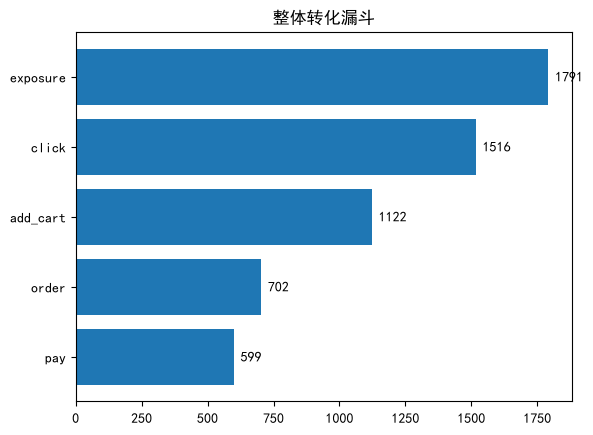

In [53]:
import matplotlib.pyplot as plt
plt.barh(funnel_df["step"][::-1], funnel_df["users"][::-1])
for i, v in enumerate(funnel_df["users"][::-1]):
    plt.text(v, i, f" {v:.0f}", va="center")
plt.title("整体转化漏斗")
plt.show()